# Data Intelligence Challenge — Ejercicios 3 y 4 (Python)
Jorge Piñeros · Sistemas de Información · Universidad EAN

Ejercicio 3: RutaExpress (retrasos y costos). Ejercicio 4: NovaMarket (clientes y fidelización). Los CSV originales no se modifican.

In [1]:
# Librerías que se usan en todo el notebook
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

os.makedirs("graficos", exist_ok=True)   # carpeta donde guardo los gráficos para el informe

# Colores que uso en los gráficos (azul = normal, naranja = lo que hay que mirar)
AZUL, NARANJA, GRIS = "#2a78d6", "#eb6834", "#9a9a95"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})

## Ejercicio 3 — RutaExpress
### E — Extraer

In [2]:
# Cargo el CSV original. encoding="utf-8-sig" quita el BOM que trae el archivo
# (sin esto la primera columna puede quedar con un carácter invisible al inicio del nombre)
df = pd.read_csv("03_RutaExpress_Envios.csv", encoding="utf-8-sig")

print("Filas y columnas:", df.shape)   # esperado: 36 filas, 7 columnas
print(df.head())                       # primeras filas, estado original
print()
df.info()                              # tipos de dato por columna
print()
print("Faltantes por columna (estado original):")
print(df.isna().sum())                 # aquí sale 1 faltante en Dias_Reales (E030)

Filas y columnas: (36, 7)
  ID_Envio    Zona Transportista  Dias_Planeados  Dias_Reales  Costo_COP  \
0     E001   Rural            T2               1          1.0      36500   
1     E002   Mixta            T3               1          2.0      29500   
2     E003  Urbana            T1               1          3.0      22500   
3     E004   Rural            T2               1          4.0      15500   
4     E005   Mixta            T3               1          1.0      40000   

      Estado  
0  Entregado  
1   Devuelto  
2  Entregado  
3  Entregado  
4   Devuelto  

<class 'pandas.DataFrame'>
RangeIndex: 36 entries, 0 to 35
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   ID_Envio        36 non-null     str    
 1   Zona            36 non-null     str    
 2   Transportista   36 non-null     str    
 3   Dias_Planeados  36 non-null     int64  
 4   Dias_Reales     35 non-null     float64
 5   Costo_COP      

### T — Transformar

In [3]:
# Guardo una copia del original para poder comparar antes/después (trazabilidad)
original = df.copy()

# 1) Zona: quito espacios y dejo formato Título. En E010 venía " urbana " (espacios + minúscula),
#    sin esto Python lo contaría como una zona distinta de "Urbana".
print("Zonas antes:", sorted(df["Zona"].unique()))
df["Zona"] = df["Zona"].str.strip().str.title()
print("Zonas después:", sorted(df["Zona"].unique()))

# 2) Columnas numéricas: errors="coerce" convierte lo que no sea número en NaN (no inventa valores)
for c in ["Dias_Planeados", "Dias_Reales", "Costo_COP"]:
    df[c] = pd.to_numeric(df[c], errors="coerce")

# 3) Costo negativo: un costo de envío no puede ser negativo (E022 = -5000).
#    Lo marco en una columna aparte para documentarlo y lo paso a NaN (no lo reemplazo por ningún valor).
df["Costo_invalido"] = df["Costo_COP"] < 0
print("Costos negativos encontrados:", int(df["Costo_invalido"].sum()))
print(df.loc[df["Costo_invalido"], ["ID_Envio", "Transportista", "Zona", "Costo_COP"]])
df.loc[df["Costo_COP"] < 0, "Costo_COP"] = np.nan

# 4) Retraso en días = días reales - planeados, pero nunca menos de 0 (llegar antes no es retraso).
#    Si falta alguno de los dos tiempos, el resultado queda NaN (E030 no tiene Dias_Reales).
df["Retraso_Dias"] = (df["Dias_Reales"] - df["Dias_Planeados"]).clip(lower=0)
df["Tiempo_invalido"] = df["Dias_Reales"].isna() | df["Dias_Planeados"].isna()
print("Filas sin tiempo válido:", int(df["Tiempo_invalido"].sum()))
print(df.loc[df["Tiempo_invalido"], ["ID_Envio", "Transportista", "Dias_Planeados", "Dias_Reales"]])

print()
print("Faltantes después de limpiar:")
print(df[["Dias_Planeados", "Dias_Reales", "Costo_COP", "Retraso_Dias"]].isna().sum())

Zonas antes: [' urbana ', 'Mixta', 'Rural', 'Urbana']
Zonas después: ['Mixta', 'Rural', 'Urbana']
Costos negativos encontrados: 1
   ID_Envio Transportista   Zona  Costo_COP
21     E022            T2  Rural      -5000
Filas sin tiempo válido: 1
   ID_Envio Transportista  Dias_Planeados  Dias_Reales
29     E030            T1               1          NaN

Faltantes después de limpiar:
Dias_Planeados    0
Dias_Reales       1
Costo_COP         1
Retraso_Dias      1
dtype: int64


### L — Cargar (exportar CSV limpio)

In [4]:
# El CSV limpio es un archivo nuevo; el original queda intacto.
df.to_csv("RutaExpress_Limpio.csv", index=False)

# Compruebo que se guardó bien volviendo a leerlo
chequeo = pd.read_csv("RutaExpress_Limpio.csv")
print("CSV limpio guardado:", chequeo.shape, "(filas, columnas)")
print(chequeo.head(3))

CSV limpio guardado: (36, 10) (filas, columnas)
  ID_Envio    Zona Transportista  Dias_Planeados  Dias_Reales  Costo_COP  \
0     E001   Rural            T2               1          1.0    36500.0   
1     E002   Mixta            T3               1          2.0    29500.0   
2     E003  Urbana            T1               1          3.0    22500.0   

      Estado  Costo_invalido  Retraso_Dias  Tiempo_invalido  
0  Entregado           False           0.0            False  
1   Devuelto           False           1.0            False  
2  Entregado           False           2.0            False  


### Indicadores

In [5]:
# Solo se evalúan las filas con tiempos válidos (35 de 36)
v = df[~df["Tiempo_invalido"]].copy()
v["Retrasado"] = v["Retraso_Dias"] > 0

a_tiempo = int((~v["Retrasado"]).sum())
retrasadas = int(v["Retrasado"].sum())
print(f"Filas con tiempos válidos: {len(v)}")
print(f"Entregas a tiempo: {a_tiempo}  |  Retrasadas: {retrasadas}")
print(f"% de retrasos: {retrasadas / len(v) * 100:.1f}%  (denominador = {len(v)} filas válidas)")
print(f"Retraso promedio general: {v['Retraso_Dias'].mean():.2f} días")

# Por transportista: cantidad, retrasadas, % retraso, retraso promedio
por_transp = v.groupby("Transportista").agg(
    envios_validos=("ID_Envio", "count"),
    retrasadas=("Retrasado", "sum"),
    pct_retraso=("Retrasado", lambda s: s.mean() * 100),
    retraso_prom_dias=("Retraso_Dias", "mean"),
    retraso_max_dias=("Retraso_Dias", "max"),
).round(2)
print()
print(por_transp)

# Costo promedio válido por zona (el costo negativo ya es NaN y pandas lo ignora en el promedio)
por_zona = df.groupby("Zona").agg(
    envios=("ID_Envio", "count"),
    costos_validos=("Costo_COP", "count"),
    costo_prom=("Costo_COP", "mean"),
    retraso_prom_dias=("Retraso_Dias", "mean"),
).round(2)
print()
print(por_zona)

# Qué hubiera pasado si NO se hubiera limpiado el costo negativo (para justificar la limpieza)
sin_limpiar = original.assign(Costo_COP=pd.to_numeric(original["Costo_COP"], errors="coerce"))
sin_limpiar["Zona"] = sin_limpiar["Zona"].str.strip().str.title()
print()
print("Costo promedio por zona SIN limpiar:")
print(sin_limpiar.groupby("Zona")["Costo_COP"].mean().round(2))

# Tablas cruzadas para entender las anomalías
print()
print(pd.crosstab(df["Transportista"], df["Estado"]))
print()
print(pd.crosstab(df["Transportista"], df["Zona"]))

Filas con tiempos válidos: 35
Entregas a tiempo: 14  |  Retrasadas: 21
% de retrasos: 60.0%  (denominador = 35 filas válidas)
Retraso promedio general: 1.20 días

               envios_validos  retrasadas  pct_retraso  retraso_prom_dias  \
Transportista                                                               
T1                         11           7        63.64               1.27   
T2                         12           7        58.33               1.25   
T3                         12           7        58.33               1.08   

               retraso_max_dias  
Transportista                    
T1                          3.0  
T2                          3.0  
T3                          3.0  

        envios  costos_validos  costo_prom  retraso_prom_dias
Zona                                                         
Mixta       12              12    29500.00               1.08
Rural       11              10    26000.00               1.36
Urbana      13              13  

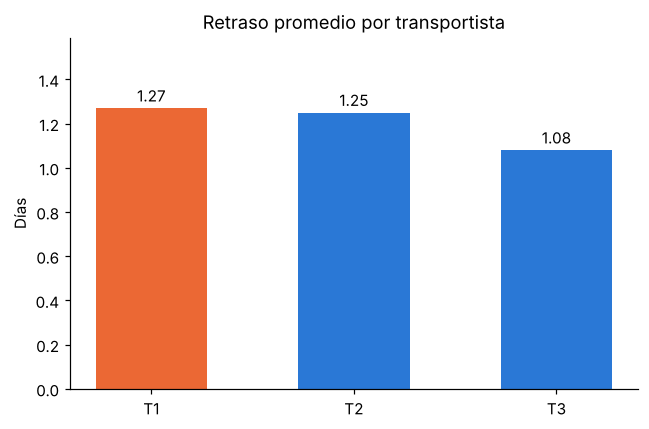

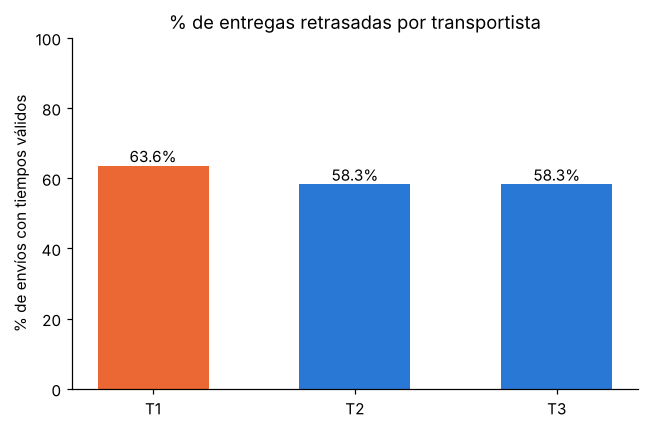

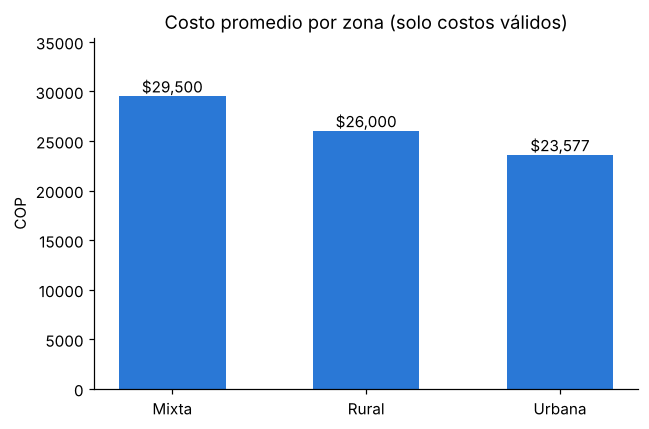

In [6]:
# Gráfico 1: retraso promedio por transportista (el naranja marca el más alto)
vals = por_transp["retraso_prom_dias"]
colores = [NARANJA if x == vals.max() else AZUL for x in vals]
fig, ax = plt.subplots(figsize=(6, 4))
barras = ax.bar(vals.index, vals.values, color=colores, width=0.55)
for b, x in zip(barras, vals.values):
    ax.text(b.get_x() + b.get_width() / 2, x + 0.03, f"{x:.2f}", ha="center", fontsize=10)
ax.set_title("Retraso promedio por transportista")
ax.set_ylabel("Días"); ax.set_ylim(0, vals.max() * 1.25)
plt.tight_layout(); plt.savefig("graficos/g3_retraso_transportista.png"); plt.show()

# Gráfico 2: % de entregas retrasadas por transportista
pct = por_transp["pct_retraso"]
colores = [NARANJA if x == pct.max() else AZUL for x in pct]
fig, ax = plt.subplots(figsize=(6, 4))
barras = ax.bar(pct.index, pct.values, color=colores, width=0.55)
for b, x in zip(barras, pct.values):
    ax.text(b.get_x() + b.get_width() / 2, x + 1, f"{x:.1f}%", ha="center", fontsize=10)
ax.set_title("% de entregas retrasadas por transportista")
ax.set_ylabel("% de envíos con tiempos válidos"); ax.set_ylim(0, 100)
plt.tight_layout(); plt.savefig("graficos/g3_pct_retraso_transportista.png"); plt.show()

# Gráfico 3: costo promedio válido por zona
cz = por_zona["costo_prom"]
fig, ax = plt.subplots(figsize=(6, 4))
barras = ax.bar(cz.index, cz.values, color=AZUL, width=0.55)
for b, x in zip(barras, cz.values):
    ax.text(b.get_x() + b.get_width() / 2, x + 400, f"${x:,.0f}", ha="center", fontsize=10)
ax.set_title("Costo promedio por zona (solo costos válidos)")
ax.set_ylabel("COP"); ax.set_ylim(0, cz.max() * 1.2)
plt.tight_layout(); plt.savefig("graficos/g3_costo_zona.png"); plt.show()

## Ejercicio 4 — NovaMarket clientes
### E — Extraer

In [7]:
cl = pd.read_csv("04_NovaMarket_Clientes.csv", encoding="utf-8-sig")

print("Filas y columnas:", cl.shape)   # esperado: 36 filas, 6 columnas
print(cl.head())
print()
cl.info()
print()
print("Faltantes por columna (estado original):")
print(cl.isna().sum())                 # 1 faltante en Gasto_90d_COP (C021)

Filas y columnas: (36, 6)
  ID_Cliente     Segmento    Ciudad  Compras_90d  Gasto_90d_COP  \
0       C001    Frecuente  Medellín            6       480000.0   
1       C002  Corporativo      Cali            3       105000.0   
2       C003        Nuevo    Bogotá            8       640000.0   
3       C004    Frecuente  Medellín            5       175000.0   
4       C005  Corporativo      Cali            2       160000.0   

   Dias_Ultima_Compra  
0                  11  
1                  22  
2                  33  
3                  44  
4                  55  

<class 'pandas.DataFrame'>
RangeIndex: 36 entries, 0 to 35
Data columns (total 6 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   ID_Cliente          36 non-null     str    
 1   Segmento            36 non-null     str    
 2   Ciudad              36 non-null     str    
 3   Compras_90d         36 non-null     int64  
 4   Gasto_90d_COP       35 non-null     

### T — Transformar

In [8]:
cl_original = cl.copy()   # copia para comparar antes/después

# 1) Ciudad: quito espacios y dejo formato Título. En C011 venía "bogotá " (minúscula + espacio).
print("Ciudades antes:", sorted(cl["Ciudad"].unique()))
cl["Ciudad"] = cl["Ciudad"].str.strip().str.title()
print("Ciudades después:", sorted(cl["Ciudad"].unique()))

# 2) Convierto a número lo que debe ser número (lo que no se pueda queda NaN)
for c in ["Compras_90d", "Gasto_90d_COP", "Dias_Ultima_Compra"]:
    cl[c] = pd.to_numeric(cl[c], errors="coerce")

# 3) Compras negativas: no puede haber -1 compras (C032). Lo marco y lo paso a NaN, sin inventar un valor.
cl["Compras_invalida"] = cl["Compras_90d"] < 0
cl["Gasto_faltante"] = cl["Gasto_90d_COP"].isna()
print("Compras negativas:", int(cl["Compras_invalida"].sum()), "| Gastos faltantes:", int(cl["Gasto_faltante"].sum()))
print(cl.loc[cl["Compras_invalida"] | cl["Gasto_faltante"],
             ["ID_Cliente", "Segmento", "Compras_90d", "Gasto_90d_COP", "Dias_Ultima_Compra"]])
cl.loc[cl["Compras_90d"] < 0, "Compras_90d"] = np.nan

# 4) Clasificación según las reglas de la guía. El orden de las reglas importa:
#    primero se revisa si faltan datos, luego Alto valor, luego En seguimiento.
def clasificar(r):
    if pd.isna(r["Compras_90d"]) or pd.isna(r["Gasto_90d_COP"]) or pd.isna(r["Dias_Ultima_Compra"]):
        return "No clasificable"
    if r["Gasto_90d_COP"] >= 250000 and r["Compras_90d"] >= 3:
        return "Alto valor"
    if r["Dias_Ultima_Compra"] > 60:
        return "En seguimiento"
    return "Otros"

cl["Categoria"] = cl.apply(clasificar, axis=1)

# Columna extra para el análisis: clientes de Alto valor que llevan más de 60 días sin comprar (riesgo de fuga)
cl["Alto_valor_en_riesgo"] = (cl["Categoria"] == "Alto valor") & (cl["Dias_Ultima_Compra"] > 60)
print()
print(cl["Categoria"].value_counts())

Ciudades antes: ['Bogotá', 'Cali', 'Medellín', 'bogotá ']
Ciudades después: ['Bogotá', 'Cali', 'Medellín']
Compras negativas: 1 | Gastos faltantes: 1
   ID_Cliente     Segmento  Compras_90d  Gasto_90d_COP  Dias_Ultima_Compra
20       C021        Nuevo            2            NaN                  49
31       C032  Corporativo           -1        35000.0                  79

Categoria
Otros              15
Alto valor         14
En seguimiento      5
No clasificable     2
Name: count, dtype: int64


### L — Cargar (exportar CSV depurado)

In [9]:
cl.to_csv("NovaMarket_Clientes_Limpio.csv", index=False)

chequeo = pd.read_csv("NovaMarket_Clientes_Limpio.csv")
print("CSV depurado guardado:", chequeo.shape, "(filas, columnas)")
print(chequeo.head(3))

CSV depurado guardado: (36, 10) (filas, columnas)
  ID_Cliente     Segmento    Ciudad  Compras_90d  Gasto_90d_COP  \
0       C001    Frecuente  Medellín          6.0       480000.0   
1       C002  Corporativo      Cali          3.0       105000.0   
2       C003        Nuevo    Bogotá          8.0       640000.0   

   Dias_Ultima_Compra  Compras_invalida  Gasto_faltante   Categoria  \
0                  11             False           False  Alto valor   
1                  22             False           False       Otros   
2                  33             False           False  Alto valor   

   Alto_valor_en_riesgo  
0                 False  
1                 False  
2                 False  


### Indicadores

In [10]:
# Clientes por categoría + gasto total y promedio (el promedio usa solo gastos válidos)
resumen = cl.groupby("Categoria").agg(
    clientes=("ID_Cliente", "count"),
    gasto_total=("Gasto_90d_COP", "sum"),
    gasto_prom=("Gasto_90d_COP", "mean"),
).round(0)
print(resumen)
print()
print("Gasto total (todos los clientes con gasto válido):", f"${cl['Gasto_90d_COP'].sum():,.0f}")
print("Gasto promedio válido:", f"${cl['Gasto_90d_COP'].mean():,.0f}", f"(sobre {cl['Gasto_90d_COP'].count()} clientes con gasto)")

# Top 5 por gasto. OJO: hay 5 clientes empatados en 640.000, así que el top 5 son exactamente esos
top5 = cl.sort_values("Gasto_90d_COP", ascending=False).head(5)
print()
print("Top 5 por gasto:")
print(top5[["ID_Cliente", "Segmento", "Ciudad", "Compras_90d", "Gasto_90d_COP", "Dias_Ultima_Compra"]])

# Clientes En seguimiento
print()
print("Clientes En seguimiento:")
print(cl[cl["Categoria"] == "En seguimiento"][["ID_Cliente", "Segmento", "Ciudad", "Compras_90d", "Gasto_90d_COP", "Dias_Ultima_Compra"]])

# Alto valor que llevan más de 60 días sin comprar: son la prioridad de recuperación
print()
print("Alto valor en riesgo (>60 días sin comprar):")
print(cl[cl["Alto_valor_en_riesgo"]][["ID_Cliente", "Segmento", "Ciudad", "Compras_90d", "Gasto_90d_COP", "Dias_Ultima_Compra"]])

# No clasificables
print()
print("No clasificables (faltan datos esenciales):")
print(cl[cl["Categoria"] == "No clasificable"][["ID_Cliente", "Segmento", "Compras_90d", "Gasto_90d_COP", "Dias_Ultima_Compra"]])

# Gasto por ciudad y categoría por segmento (contexto)
print()
print(cl.groupby("Ciudad")["Gasto_90d_COP"].agg(["count", "sum"]))
print()
print(pd.crosstab(cl["Segmento"], cl["Categoria"]))

                 clientes  gasto_total  gasto_prom
Categoria                                         
Alto valor             14    6880000.0    491429.0
En seguimiento          5     595000.0    119000.0
No clasificable         2      35000.0     35000.0
Otros                  15    2370000.0    158000.0

Gasto total (todos los clientes con gasto válido): $9,880,000
Gasto promedio válido: $282,286 (sobre 35 clientes con gasto)

Top 5 por gasto:
   ID_Cliente     Segmento    Ciudad  Compras_90d  Gasto_90d_COP  \
2        C003        Nuevo    Bogotá          8.0       640000.0   
18       C019    Frecuente  Medellín          8.0       640000.0   
10       C011  Corporativo    Bogotá          8.0       640000.0   
34       C035  Corporativo      Cali          8.0       640000.0   
26       C027        Nuevo    Bogotá          8.0       640000.0   

    Dias_Ultima_Compra  
2                   33  
18                  27  
10                  30  
34                  21  
26               

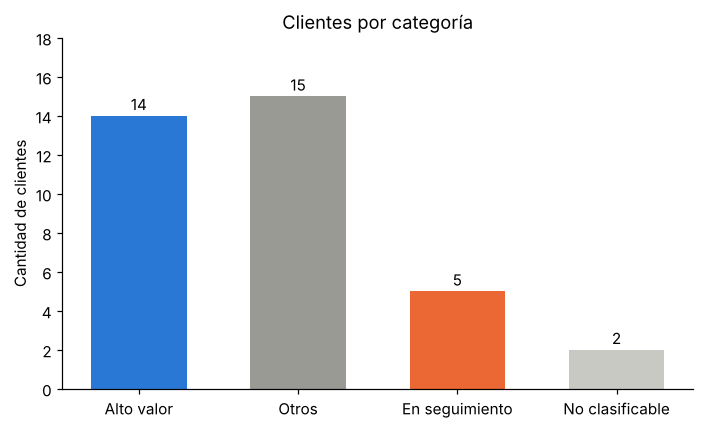

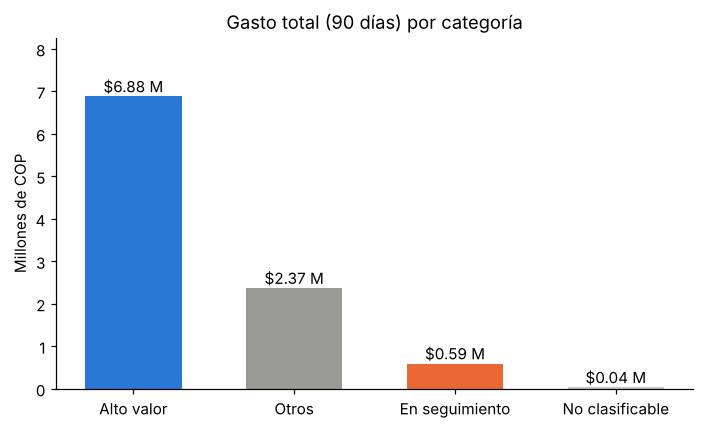

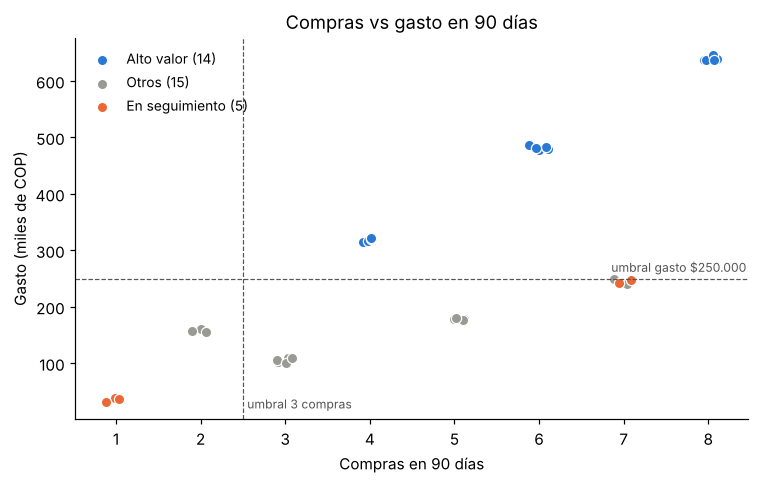

En el gráfico: 34 clientes (faltan C021 y C032 por datos inválidos)


In [11]:
# Gráfico 4: barras de clientes por categoría
orden = ["Alto valor", "Otros", "En seguimiento", "No clasificable"]
conteo = cl["Categoria"].value_counts().reindex(orden)
colores = [AZUL, GRIS, NARANJA, "#c9c9c4"]
fig, ax = plt.subplots(figsize=(6.5, 4))
barras = ax.bar(conteo.index, conteo.values, color=colores, width=0.6)
for b, x in zip(barras, conteo.values):
    ax.text(b.get_x() + b.get_width() / 2, x + 0.3, str(int(x)), ha="center", fontsize=10)
ax.set_title("Clientes por categoría")
ax.set_ylabel("Cantidad de clientes"); ax.set_ylim(0, conteo.max() * 1.2)
plt.tight_layout(); plt.savefig("graficos/g4_clientes_categoria.png"); plt.show()

# Gráfico 5: gasto total por categoría
gasto = cl.groupby("Categoria")["Gasto_90d_COP"].sum().reindex(orden)
fig, ax = plt.subplots(figsize=(6.5, 4))
barras = ax.bar(gasto.index, gasto.values / 1e6, color=colores, width=0.6)
for b, x in zip(barras, gasto.values / 1e6):
    ax.text(b.get_x() + b.get_width() / 2, x + 0.1, f"${x:.2f} M", ha="center", fontsize=10)
ax.set_title("Gasto total (90 días) por categoría")
ax.set_ylabel("Millones de COP"); ax.set_ylim(0, (gasto.max() / 1e6) * 1.2)
plt.tight_layout(); plt.savefig("graficos/g4_gasto_categoria.png"); plt.show()

# Gráfico 6: dispersión compras vs gasto.
# Muchos clientes tienen exactamente los mismos valores, así que muevo un poquito los puntos (jitter)
# solo para que se vean todos. Los valores reales no cambian.
rng = np.random.default_rng(1)
p = cl.dropna(subset=["Compras_90d", "Gasto_90d_COP"]).copy()   # C021 y C032 no se pueden graficar
fig, ax = plt.subplots(figsize=(7, 4.5))
estilos = {"Alto valor": AZUL, "Otros": GRIS, "En seguimiento": NARANJA}
for cat, col in estilos.items():
    s = p[p["Categoria"] == cat]
    ax.scatter(s["Compras_90d"] + rng.uniform(-0.12, 0.12, len(s)),
               s["Gasto_90d_COP"] / 1000 + rng.uniform(-6, 6, len(s)),
               s=45, color=col, edgecolor="white", linewidth=0.8, label=f"{cat} ({len(s)})")
ax.axhline(250, color="#555555", linestyle="--", linewidth=0.8)
ax.axvline(2.5, color="#555555", linestyle="--", linewidth=0.8)
ax.text(8.45, 262, "umbral gasto $250.000", ha="right", fontsize=8, color="#555555")
ax.text(2.55, 20, "umbral 3 compras", fontsize=8, color="#555555")
ax.set_title("Compras vs gasto en 90 días")
ax.set_xlabel("Compras en 90 días"); ax.set_ylabel("Gasto (miles de COP)")
ax.legend(frameon=False, fontsize=9, loc="upper left")
plt.tight_layout(); plt.savefig("graficos/g4_dispersion_compras_gasto.png"); plt.show()
print(f"En el gráfico: {len(p)} clientes (faltan C021 y C032 por datos inválidos)")